# 01. 타이밍과 SPA로 비밀번호 찾기

번들 펌웨어는 비밀번호를 앞에서부터 비교하고 첫 불일치에서 바로 `break`합니다.

```text
입력 h0p?  ── 비교 h ✓ ── 비교 0 ✓ ── 비교 p ✓ ── 비교 ? ✗ ── 종료
입력 a...  ── 비교 a ✗ ── 종료
```

앞부분이 맞을수록 비교 횟수가 늘고 파형에도 다음 비교가 추가됩니다. 먼저 고정 seed로 만든 합성 파형에서 이 차이를 확인합니다.

## 후보 파형 준비

첫 글자 후보 36개와 항상 틀리는 기준 입력의 파형을 만듭니다. `correct_index`와 `wrong_index`는 그래프에서 `h`와 `a`를 바로 꺼내 비교하려고 사용합니다. 이 셀을 실행하면 아직 공격은 하지 않고 비교할 데이터만 준비합니다.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from cw_sca_tutorial.synthetic import PASSWORD_ALPHABET, password_candidate_batch

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True})
candidates, reference = password_candidate_batch("")
correct_index = PASSWORD_ALPHABET.index("h")
wrong_index = PASSWORD_ALPHABET.index("a")

## 맞는 후보와 틀린 후보 비교

왼쪽 그래프에서는 기준 파형, `a`, `h`를 겹쳐 봅니다. 오른쪽 그래프는 각 후보에서 기준 파형을 뺀 결과입니다. `h`를 넣었을 때만 다음 문자 비교로 넘어가므로 차이 파형에 추가 활동이 남습니다.

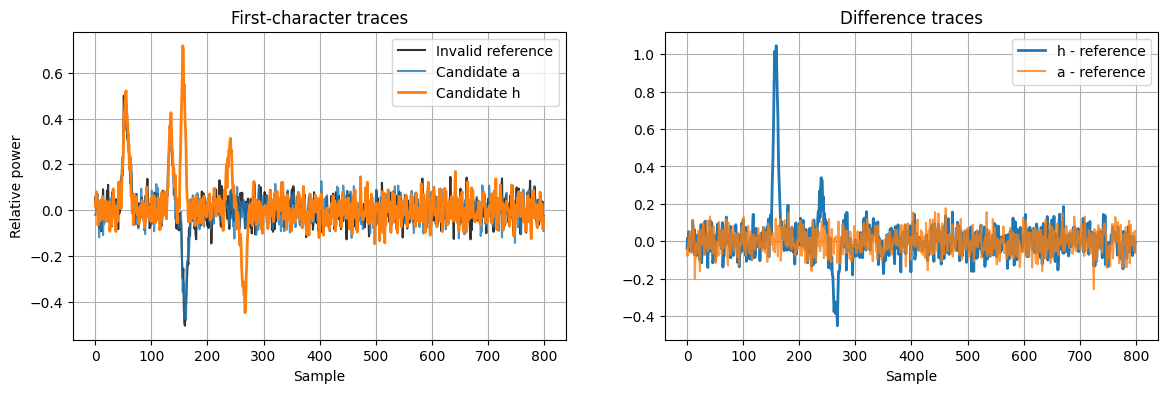

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(reference, label="Invalid reference", color="black", alpha=.8)
axes[0].plot(candidates[wrong_index], label="Candidate a", alpha=.8)
axes[0].plot(candidates[correct_index], label="Candidate h", linewidth=2)
axes[0].set(title="First-character traces", xlabel="Sample", ylabel="Relative power")
axes[0].legend()
axes[1].plot(candidates[correct_index] - reference, label="h - reference", linewidth=2)
axes[1].plot(candidates[wrong_index] - reference, label="a - reference", alpha=.8)
axes[1].set(title="Difference traces", xlabel="Sample")
axes[1].legend()
plt.show()

## 차이를 점수로 계산하기

기준 파형과 후보 파형의 절댓값 차이 합(SAD)을 계산합니다. 양수와 음수가 서로 지워지지 않도록 차이의 절댓값을 먼저 구합니다.

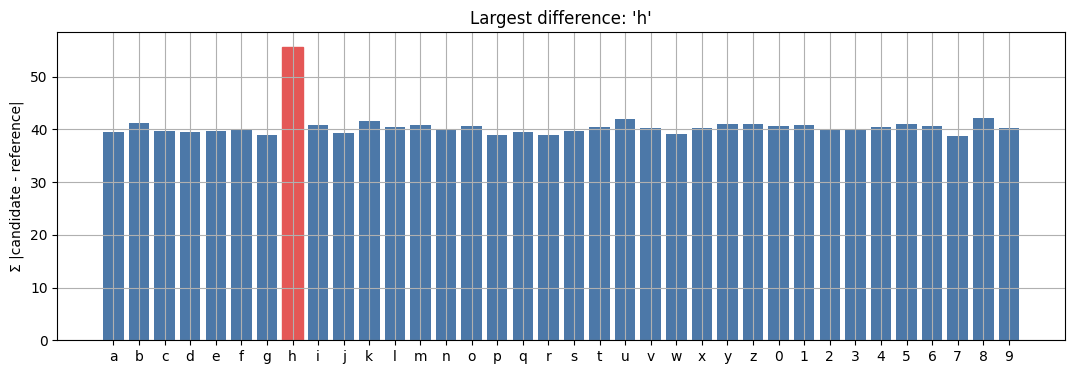

In [3]:
scores = np.sum(np.abs(candidates - reference), axis=1)
plt.figure(figsize=(13, 4))
bars = plt.bar(list(PASSWORD_ALPHABET), scores, color="#4c78a8")
bars[int(np.argmax(scores))].set_color("#e45756")
plt.ylabel("Σ |candidate - reference|")
plt.title(f"Largest difference: '{PASSWORD_ALPHABET[int(np.argmax(scores))]}'")
plt.show()

## 전체 비밀번호 복구

지금까지 찾은 접두사 뒤에 36개 후보를 차례로 붙입니다. 기준 파형과 가장 큰 차이를 만든 문자를 고르는 과정을 다섯 번 반복합니다.

In [4]:
prefix = ""
score_rows = []
for position in range(5):
    candidates, reference = password_candidate_batch(prefix)
    scores = np.sum(np.abs(candidates - reference), axis=1)
    score_rows.append(scores)
    prefix += PASSWORD_ALPHABET[int(np.argmax(scores))]
    print(f"{position + 1}번째 글자 → {prefix}")

score_rows = np.stack(score_rows)
assert prefix == "h0px3"

1번째 글자 → h
2번째 글자 → h0
3번째 글자 → h0p
4번째 글자 → h0px
5번째 글자 → h0px3


## 위치별 후보 점수

앞 셀에서 저장한 다섯 단계의 점수를 heatmap으로 표시합니다. 각 행에서 가장 밝은 칸을 왼쪽부터 읽으면 `h`, `0`, `p`, `x`, `3`이 됩니다. 한 글자를 잘못 고르면 다음 단계의 접두사도 틀어지므로 매 행에서 하나의 후보가 충분히 분리되는지 확인합니다.

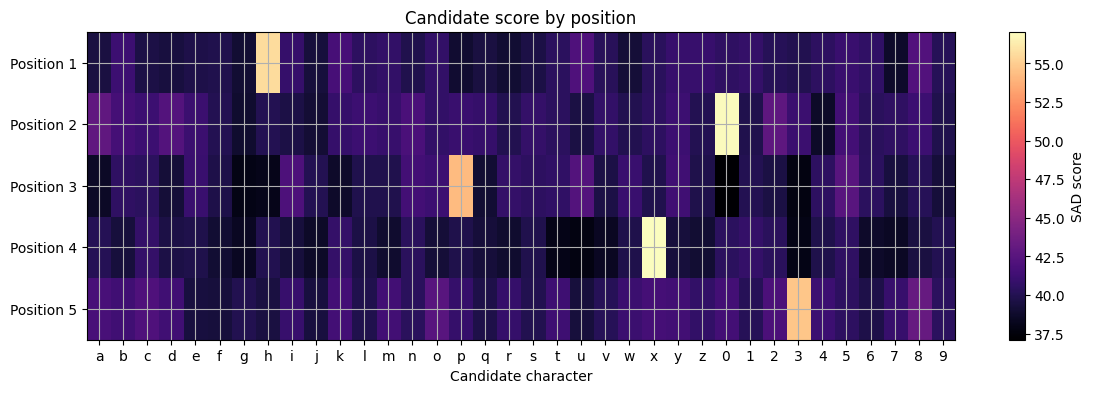

In [5]:
fig, ax = plt.subplots(figsize=(14, 4))
image = ax.imshow(score_rows, aspect="auto", cmap="magma")
ax.set_xticks(range(len(PASSWORD_ALPHABET)), list(PASSWORD_ALPHABET))
ax.set_yticks(range(5), ["Position 1", "Position 2", "Position 3", "Position 4", "Position 5"])
ax.set(title="Candidate score by position", xlabel="Candidate character")
fig.colorbar(image, ax=ax, label="SAD score")
plt.show()